# Size tiers: one model or several?

What drives price for a starter home may differ from what drives it for a mansion. This notebook tests whether separate models per size tier beat one model for all homes.

Homes are routed by `LivingArea`, which is known before listing, never by price. Every home still gets a prediction: the tiers together cover all sizes.

The model is the current best (Random Forest + school districts). Setup as before: X = 18 months, compared on the 6 validation months 2025-10 to 2026-03. The test month, 2026-04, is held out and never scored. Tiers didn't help, so `SizeTieredModel` lives in this notebook only.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, RegressorMixin, clone

from idx_exchange_data_science import dataset_a as da
from idx_exchange_data_science import features as ft
from idx_exchange_data_science.modeling import backtest, build_model, gain_summary, median_ape_by, random_forest
from idx_exchange_data_science.splits import split, validation_months

pd.set_option("display.float_format", "{:,.4f}".format)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

X = 18
EVAL_MONTHS = validation_months("2026-04", n_months=6)  # 2025-10 to 2026-03; 2026-04 is the held-out test month
RESULTS_DIR = Path("../results")
SIZE_BANDS = [0, 1000, 1250, 1500, 1750, 2000, 2500, 3000, 4000, 5000, np.inf]

df = ft.build_table()


class SizeTieredModel(RegressorMixin, BaseEstimator):
    """A separate copy of `model` per size tier, routed on a column known before listing.

    cutoffs=[4000] fits one model on homes under 4,000 sq ft and one on the rest. Every
    home gets a prediction; rows with a missing `column` go to the tier of the training median.
    """

    def __init__(self, model, cutoffs, column="LivingArea"):
        self.model = model
        self.cutoffs = cutoffs
        self.column = column

    def tiers(self, X):
        size = X[self.column].fillna(self.fill_value_)
        return np.searchsorted(sorted(self.cutoffs), size.to_numpy(), side="right")

    def fit(self, X, y):
        self.fill_value_ = X[self.column].median()
        tier = self.tiers(X)
        self.models_ = [clone(self.model).fit(X[tier == t], y[tier == t]) for t in range(len(self.cutoffs) + 1)]
        return self

    def predict(self, X):
        tier = self.tiers(X)
        pred = np.empty(len(X))
        for t, model in enumerate(self.models_):
            if (tier == t).any():
                pred[tier == t] = model.predict(X[tier == t])
        return pred


def forest():
    return build_model(random_forest(), da.make_preprocessor(ft.DISTRICT_NUMERIC_COLS, ft.DISTRICT_COLS))


def size_band(frame):
    return pd.cut(frame["LivingArea"], SIZE_BANDS, right=False)

## 1. Where would a split go?
Two views of the 18 months of training data before the last validation month (2026-03): price per square foot by size, and how many sales each size band has.

In [2]:
train, _ = split(df, EVAL_MONTHS[-1], X)
by_size = train.groupby(size_band(train), observed=True).agg(
    sales=(da.TARGET, "size"),
    median_price=(da.TARGET, "median"),
    median_price_per_sqft=(da.TARGET, lambda p: (p / train.loc[p.index, "LivingArea"]).median()),
)
by_size["share"] = by_size["sales"] / by_size["sales"].sum()
by_size

,sales,median_price,median_price_per_sqft,share
LivingArea,,,,
"[0.0, 1000.0)",10717,"599,000.0000",707.3991,0.0568
"[1000.0, 1250.0)",22219,"715,000.0000",629.6296,0.1177
"[1250.0, 1500.0)",27664,"770,000.0000",561.7573,0.1465
"[1500.0, 1750.0)",27954,"829,000.0000",510.9115,0.1480
"[1750.0, 2000.0)",23839,"885,000.0000",475.6815,0.1263
"[2000.0, 2500.0)",33718,"1,033,000.0000",466.7917,0.1786
"[2500.0, 3000.0)",19232,"1,250,000.0000",459.0595,0.1019
"[3000.0, 4000.0)",16322,"1,700,000.0000",501.9508,0.0864
"[4000.0, 5000.0)",4633,"2,640,000.0000",600.0000,0.0245


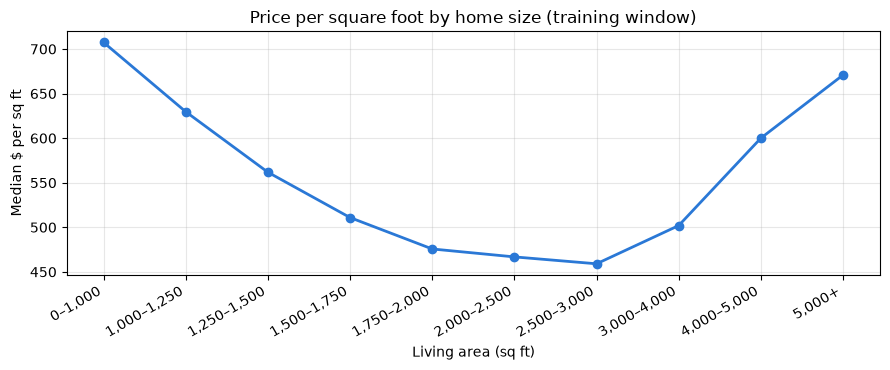

In [3]:
labels = [f"{int(b.left):,}+" if np.isinf(b.right) else f"{int(b.left):,}–{int(b.right):,}" for b in by_size.index]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(len(by_size)), by_size["median_price_per_sqft"], marker="o", markersize=6, linewidth=2, color=COLORS[0])
ax.set(xticks=range(len(by_size)), xlabel="Living area (sq ft)", ylabel="Median $ per sq ft",
       title="Price per square foot by home size (training window)")
ax.set_xticklabels(labels, rotation=30, ha="right")
ax.grid(alpha=0.3)
plt.tight_layout()

**Observations**
- **Price per square foot is U-shaped.** It falls from \$707 for homes under 1,000 sq ft to \$459 at 2,500–3,000 sq ft, then rises again to \$671 above 5,000 sq ft. For small homes the land and location dominate the price. For large homes, size marks a luxury property. So the size–price relationship does bend, around 2,500–3,000 sq ft.
- **Large homes are rare.** Only 3.8% of training sales are 4,000 sq ft or more (about 7,200 sales), and 1.3% are over 5,000.

## 2. Configurations
- **Single model:** one forest for all homes (current best).
- **2 tiers at 3,000 sq ft:** where price per square foot turns back up.
- **2 tiers at 4,000 sq ft:** a separate model just for the largest homes.
- **3 tiers at 1,250 and 4,000 sq ft:** small, middle and large.

Each tier gets its own copy of the same forest, with its own imputation and target encoding fit on that tier's training rows.

In [4]:
CONFIGS = {
    "Single model": forest(),
    "2 tiers (3,000)": SizeTieredModel(forest(), cutoffs=[3000]),
    "2 tiers (4,000)": SizeTieredModel(forest(), cutoffs=[4000]),
    "3 tiers (1,250 / 4,000)": SizeTieredModel(forest(), cutoffs=[1250, 4000]),
}

## 3. Validation

In [5]:
results, predictions = backtest(CONFIGS, df, EVAL_MONTHS, X)
validation = results.groupby("model")[["r2", "mae", "mape", "median_ape"]].mean().loc[list(CONFIGS)]
validation.join(gain_summary(results, reference="Single model"))

,r2,mae,mape,median_ape,mean gain,std gain,months improved (of 6)
model,,,,,,,
Single model,0.8923,"151,207.2719",0.1196,0.0774,NaN,NaN,NaN
"2 tiers (3,000)",0.8919,"151,594.5785",0.1199,0.0775,-0.0004,0.0011,2.0000
"2 tiers (4,000)",0.8911,"151,731.6668",0.1199,0.0771,-0.0012,0.0023,1.0000
"3 tiers (1,250 / 4,000)",0.8910,"151,839.5774",0.1202,0.0770,-0.0013,0.0022,1.0000


**Observations**
- **No tiered configuration beats the single model.** All three are slightly worse on mean validation R² (−0.0004 to −0.0013) and improve in only 1–2 of 6 months.
- The forest already splits on living area wherever that helps, so it effectively builds its own size tiers, and it chooses them per location rather than at one fixed cutoff. Forcing a cutoff only takes training data away from each tier.

### Error by size
Median absolute percentage error over the 6 validation months, by size band. This is where tiers should help if they help at all.

In [6]:
evaluated = df.loc[predictions.index]
error_by_size = median_ape_by(predictions, evaluated[da.TARGET], size_band(evaluated))
error_by_size.insert(0, "sales", evaluated.groupby(size_band(evaluated), observed=True).size())
error_by_size

,sales,Single model,"2 tiers (3,000)","2 tiers (4,000)","3 tiers (1,250 / 4,000)"
LivingArea,,,,,
"[0.0, 1000.0)",3268,8.7654,8.9302,8.9117,8.8361
"[1000.0, 1250.0)",6915,7.2594,7.3028,7.3078,7.5615
"[1250.0, 1500.0)",8635,7.0074,7.0046,6.9436,6.9651
"[1500.0, 1750.0)",8723,6.9331,6.9153,6.8370,6.9064
"[1750.0, 2000.0)",7437,7.0918,7.0785,7.0958,7.1388
"[2000.0, 2500.0)",10655,7.3804,7.3807,7.3393,7.3086
"[2500.0, 3000.0)",6231,8.4018,8.2876,8.3312,8.2367
"[3000.0, 4000.0)",5217,9.9216,10.2730,9.8577,9.7797
"[4000.0, 5000.0)",1509,12.2522,12.3623,13.4258,13.4258


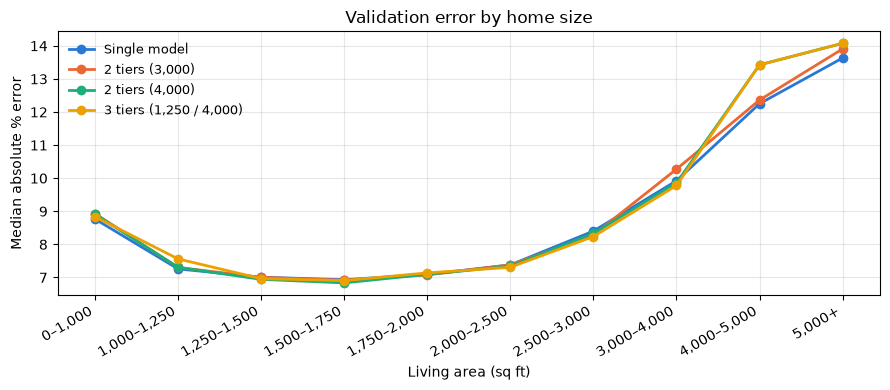

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
for color, name in zip(COLORS, CONFIGS):
    ax.plot(range(len(error_by_size)), error_by_size[name], marker="o", markersize=6, linewidth=2, color=color, label=name)
ax.set(xticks=range(len(error_by_size)), xlabel="Living area (sq ft)", ylabel="Median absolute % error",
       title="Validation error by home size")
ax.set_xticklabels(labels, rotation=30, ha="right")
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()

### Homes near a cutoff
Homes just either side of a cutoff go to different models. Within 250 sq ft of each cutoff, how do the tiered predictions compare with the single model?

In [8]:
pct_error = predictions.sub(evaluated[da.TARGET], axis=0).abs().div(evaluated[da.TARGET], axis=0) * 100
near = []
for name, cutoffs in [("2 tiers (3,000)", [3000]), ("2 tiers (4,000)", [4000]), ("3 tiers (1,250 / 4,000)", [1250, 4000])]:
    for cutoff in cutoffs:
        rows = (evaluated["LivingArea"] - cutoff).abs() < 250
        near.append({"config": name, "cutoff": cutoff, "sales": rows.sum(),
                     "single model": pct_error.loc[rows, "Single model"].median(),
                     "tiered": pct_error.loc[rows, name].median()})
pd.DataFrame(near)

,config,cutoff,sales,single model,tiered
0,"2 tiers (3,000)",3000,4616,8.9836,9.0299
1,"2 tiers (4,000)",4000,1292,11.4249,11.8649
2,"3 tiers (1,250 / 4,000)",1250,15449,7.1214,7.2264
3,"3 tiers (1,250 / 4,000)",4000,1292,11.4249,11.9303


**Observations**
- **Tiers make the largest homes worse, not better.** At 4,000–5,000 sq ft the tiered models have 12.4–13.4% median error vs 12.3% for the single model, and above 5,000 sq ft 13.9–14.1% vs 13.6% (800 sales). A separate model for large homes has far fewer rows to learn from. The large-home error looks like missing information (views, finishes, exact street) rather than a model mixing up small and large homes.
- **Homes near a cutoff do slightly worse with tiers,** most at 4,000 sq ft (11.9% vs 11.4% within 250 sq ft of it). On each side of the cutoff the tier model sees only the homes on its own side.

## Summary
- **Keep one model for all sizes.** Splitting at 3,000 or 4,000 sq ft, or into three tiers, doesn't improve validation scores.
- **The size–price relationship does change with size, but the forest already handles that** by splitting on living area itself.
- **Large homes remain the weakest segment** (about 14% median error above 5,000 sq ft). Better features for them, such as views, distance to the coast or comparable sales, are more promising than a separate model.
- Since the split itself doesn't help, a simpler model for the large tier (e.g. linear regression) isn't worth testing: in `04_model_comparison.ipynb` linear regression was already the weakest model on the most expensive homes.

In [9]:
validation.join(gain_summary(results, reference="Single model")).reset_index().to_csv(
    RESULTS_DIR / "size_tiers_comparison.csv", index=False)
results.to_csv(RESULTS_DIR / "size_tiers_backtest.csv", index=False)